In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import scipy.stats
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import seasonal_decompose

In [2]:
ibm_wmt = yf.download(tickers='IBM WMT', period='5y', interval='1mo', rounding=True)
ibm_wmt

[*********************100%***********************]  2 of 2 completed


Price        Close            High             Low            Open          \
Ticker         IBM     WMT     IBM     WMT     IBM     WMT     IBM     WMT   
Date                                                                         
2021-11-01   98.00   44.03  104.43   47.59   95.87   43.84  100.05   46.96   
2021-12-01  111.86   45.49  112.97   46.07   97.55   42.52   98.96   44.17   
2022-01-01  111.78   43.95  119.01   46.10  103.93   42.11  112.20   45.27   
2022-02-01  103.76   42.49  117.58   44.64  100.63   41.50  113.29   43.77   
2022-03-01  110.12   47.00  112.71   47.51  102.23   42.61  103.90   42.88   
2022-04-01  111.98   48.28  120.17   50.74  105.80   46.97  109.82   47.23   
2022-05-01  119.02   40.74  119.87   49.09  107.84   37.15  114.01   49.08   
2022-06-01  121.03   38.51  124.07   40.84  113.88   37.34  119.73   40.70   
2022-07-01  112.12   41.83  121.62   42.25  107.27   38.03  120.87   38.62   
2022-08-01  111.50   42.17  120.95   45.40  111.46   39.80  113.50   41.69   
2022-09-01  103.13   41.26  113.71   43.98  102.96   40.81  111.46   42.16   
2022-10-01  120.04   45.28  120.54   45.51  100.30   40.74  104.30   41.43   
2022-11-01  130.79   48.49  132.16   49.20  117.68   43.99  121.44   45.48   
2022-12-01  123.76   45.28  134.58   49.05  120.52   44.96  131.74   48.55   
2023-01-01  118.35   45.94  129.28   47.22  116.81   44.12  123.94   45.52   
2023-02-01  114.97   45.39  122.17   47.37  114.58   44.29  119.59   45.87   
2023-03-01  116.56   47.28  116.91   47.60  108.22   43.64  114.62   45.23   
2023-04-01  112.40   48.41  117.91   49.30  110.76   47.14  116.46   47.37   
2023-05-01  115.90   47.27  117.23   49.68  108.65   46.67  113.88   48.61   
2023-06-01  120.60   50.59  125.71   50.93  115.17   46.97  115.76   47.06   
2023-07-01  129.95   51.45  130.33   51.80  118.57   49.39  120.25   50.47   
2023-08-01  133.86   52.52  134.68   52.65  127.42   50.07  131.51   51.66   
2023-09-01  127.91   51.66  138.51   53.57  127.28   51.42  134.25   52.61   
2023-10-01  131.87   52.78  131.97   53.08  123.87   48.98  127.67   51.51   
2023-11-01  146.20   50.29  146.23   54.89  133.19   49.78  133.69   53.04   
2023-12-01  150.80   51.11  153.37   51.33  145.68   48.48  146.06   50.37   
2024-01-01  169.34   53.57  181.55   54.40  145.58   50.45  150.13   50.98   
2024-02-01  172.16   57.00  175.80   58.79  166.31   53.55  170.85   53.72   
2024-03-01  177.67   58.72  185.32   60.17  172.30   56.80  172.58   57.38   
2024-04-01  154.64   57.92  179.83   59.42  153.76   57.15  176.78   58.86   
2024-05-01  156.78   64.40  164.87   64.53  152.81   57.37  155.69   58.08   
2024-06-01  162.51   66.31  167.69   67.61  153.66   63.81  156.49   64.15   
2024-07-01  180.55   67.22  184.42   69.85  162.92   65.86  162.98   66.48   
2024-08-01  191.60   75.85  191.63   76.08  172.33   65.47  182.76   67.67   
2024-09-01  209.56   79.30  212.47   80.14  188.95   74.93  191.39   75.94   
2024-10-01  195.95   80.48  225.00   81.85  192.90   77.56  209.13   79.23   
2024-11-01  217.26   90.84  220.07   90.98  194.96   80.08  198.49   81.05   
2024-12-01  210.01   88.93  228.66   94.67  207.93   87.51  217.34   91.36   
2025-01-01  244.28   96.61  250.11   97.44  205.03   88.11  211.92   88.56   
2025-02-01  242.78   97.06  255.55  103.64  237.10   90.67  242.74   95.25   
2025-03-01  239.14   86.64  256.25   98.19  228.14   82.78  244.99   96.70   
2025-04-01  232.56   95.98  243.11   96.50  206.29   78.77  238.53   86.40   
2025-05-01  250.80   97.67  260.69   98.68  230.36   90.91  233.74   95.99   
2025-06-01  285.38   96.74  286.72   99.81  249.02   92.43  249.63   97.79   
2025-07-01  245.08   96.94  286.18   98.29  244.18   93.23  285.16   96.56   
2025-08-01  237.32   96.17  248.54  103.85  227.45   94.62  245.04   97.18   
2025-09-01  275.01  102.20  281.53  105.22  232.21   95.70  234.80   96.42   
2025-10-01  299.62  100.34  311.26  108.67  256.88   99.04  273.10  101.70   
2025-11-01  302.42  10

In [3]:
ibm_wmt = ibm_wmt["Close"]
ibm_wmt

Ticker,IBM,WMT
Date,,
2021-11-01,98.00,44.03
2021-12-01,111.86,45.49
2022-01-01,111.78,43.95
2022-02-01,103.76,42.49
2022-03-01,110.12,47.00
2022-04-01,111.98,48.28
2022-05-01,119.02,40.74
2022-06-01,121.03,38.51
2022-07-01,112.12,41.83


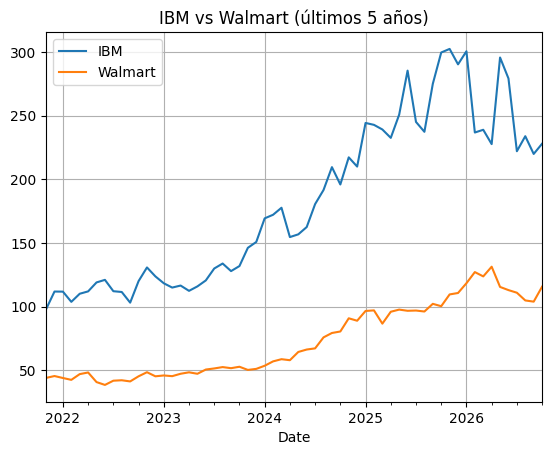

In [4]:
ibm_wmt["IBM"].plot()
ibm_wmt["WMT"].plot()
plt.legend(["IBM", "Walmart"])
plt.title("IBM vs Walmart (últimos 5 años)")
plt.grid()
plt.show()

## Descomposición de las series

In [11]:
rend_ibm_wmt = ibm_wmt.pct_change()
rend_ibm_wmt = rend_ibm_wmt.dropna()
rend_ibm_wmt

Ticker,IBM,WMT
Date,,
2021-12-01,0.141429,0.033159
2022-01-01,-0.000715,-0.033854
2022-02-01,-0.071748,-0.033220
2022-03-01,0.061295,0.106143
2022-04-01,0.016891,0.027234
2022-05-01,0.062868,-0.156172
2022-06-01,0.016888,-0.054737
2022-07-01,-0.073618,0.086211
2022-08-01,-0.005530,0.008128


In [12]:
correlacion = rend_ibm_wmt["IBM"].corr(rend_ibm_wmt["WMT"])
print("Correlación entre IBM y Walmart:", correlacion)

Correlación entre IBM y Walmart: 0.06508075864854684


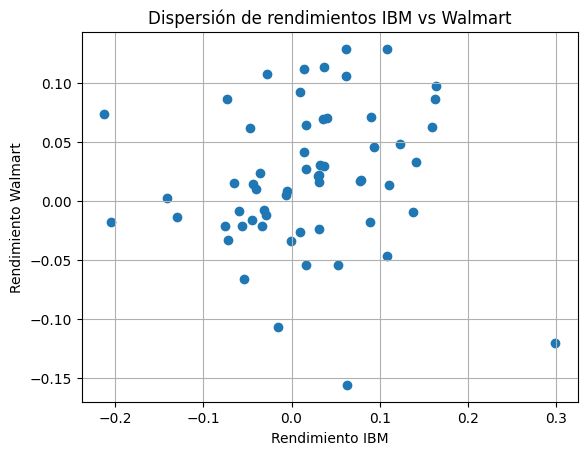

In [13]:
plt.scatter(rend_ibm_wmt["IBM"], rend_ibm_wmt["WMT"])
plt.xlabel("Rendimiento IBM")
plt.ylabel("Rendimiento Walmart")
plt.title("Dispersión de rendimientos IBM vs Walmart")
plt.grid()
plt.show()

In [14]:
ibm = yf.download(tickers="IBM", period="3Y", interval="1d", rounding=True)
ibm = ibm["Close"]

wmt = yf.download(tickers="WMT", period="3Y", interval="1d", rounding=True)
wmt = wmt["Close"]

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


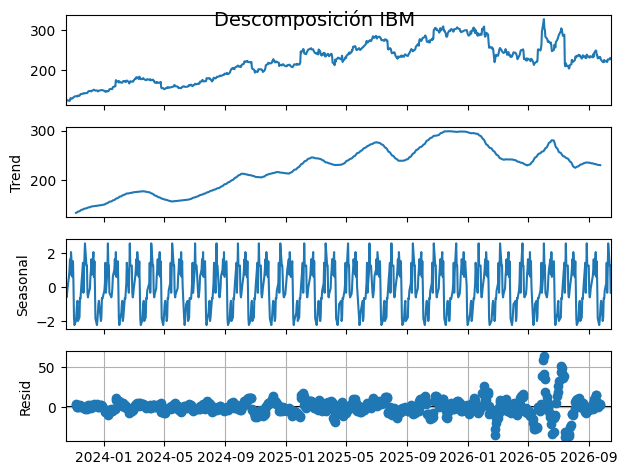

In [15]:
decomposed_ibm = sm.tsa.seasonal_decompose(ibm, period=30)

figure = decomposed_ibm.plot()
plt.grid()
plt.suptitle("Descomposición IBM", fontsize=14)
plt.show()

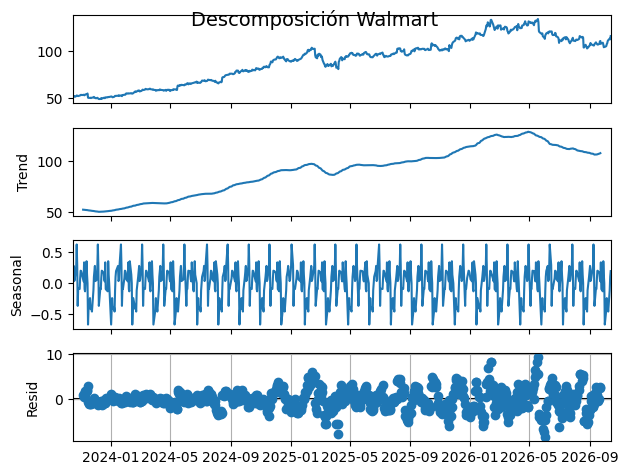

In [16]:
decomposed_wmt = sm.tsa.seasonal_decompose(wmt, period=30)

figure = decomposed_wmt.plot()
plt.grid()
plt.suptitle("Descomposición Walmart", fontsize=14)
plt.show()

## Correlogramas

In [17]:
acf_ibm = acf(ibm)
acf_ibm

array([1.        , 0.99027433, 0.97987896, 0.96878076, 0.95808709,
       0.94731101, 0.93669841, 0.92592915, 0.91539277, 0.90579887,
       0.89674189, 0.88859643, 0.88123432, 0.87366044, 0.86646916,
       0.86061615, 0.85588009, 0.85112089, 0.8459789 , 0.84100498,
       0.83606553, 0.83115796, 0.82561664, 0.81991148, 0.81290587,
       0.80477034, 0.79564142, 0.78745102, 0.77862256])

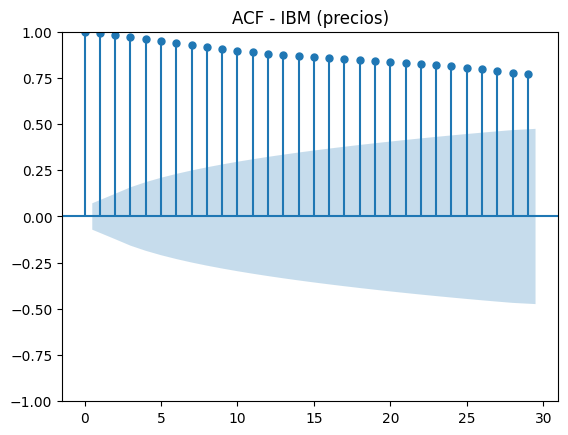

In [18]:
plot_acf(ibm, alpha=0.05)
plt.title("ACF - IBM (precios)")
plt.show()

In [19]:
acf_wmt = acf(wmt)
acf_wmt

array([1.        , 0.99566197, 0.99130307, 0.98709511, 0.98301941,
       0.97896338, 0.9752682 , 0.97169963, 0.96811182, 0.96463751,
       0.96123801, 0.95783133, 0.95448551, 0.9511507 , 0.94778373,
       0.94445275, 0.94093893, 0.93743526, 0.93427171, 0.93103247,
       0.92777096, 0.92432058, 0.92097955, 0.91778448, 0.91427477,
       0.91076078, 0.90745467, 0.90406541, 0.9003771 ])

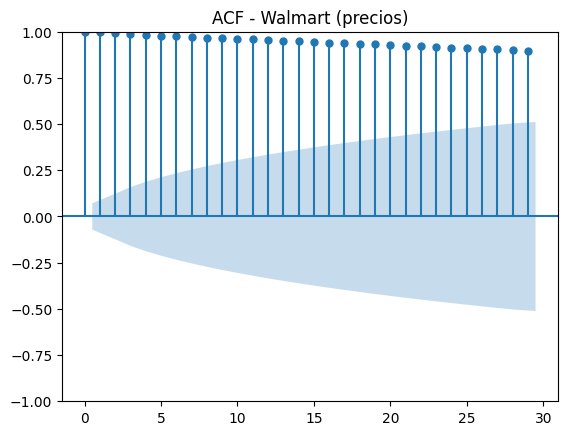

In [20]:
plot_acf(wmt, alpha=0.05)
plt.title("ACF - Walmart (precios)")
plt.show()

In [21]:
rend_ibm = ibm.pct_change().dropna()
rend_wmt = wmt.pct_change().dropna()

acf_rend_ibm = acf(rend_ibm)
acf_rend_wmt = acf(rend_wmt)
print("ACF rendimientos IBM:", acf_rend_ibm[:5])
print("ACF rendimientos Walmart:", acf_rend_wmt[:5])

ACF rendimientos IBM: [ 1.          0.04050408  0.03775623 -0.02373154  0.0032909 ]
ACF rendimientos Walmart: [ 1.          0.03207883 -0.03695952 -0.01283537 -0.02918214]


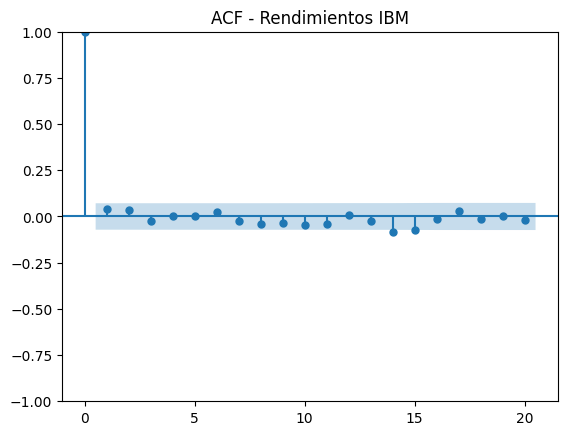

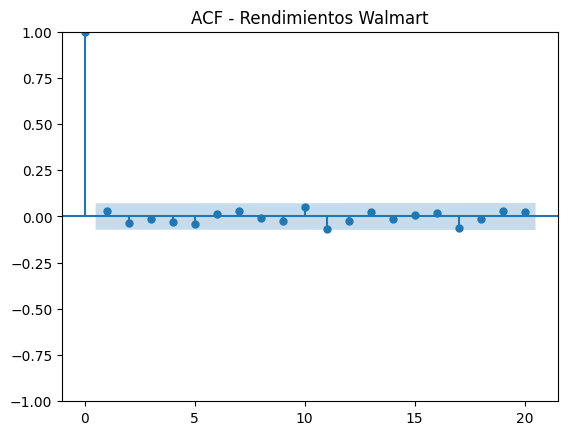

In [22]:
plot_acf(rend_ibm, alpha=0.05, lags=20)
plt.title("ACF - Rendimientos IBM")
plt.show()

plot_acf(rend_wmt, alpha=0.05, lags=20)
plt.title("ACF - Rendimientos Walmart")
plt.show()

## Prueba de Dickey-Fuller

In [23]:
#Prueba Dickey-Fuller para los precios de IBM
resultado = adfuller(ibm)
print("El valor p de la prueba para IBM es:", resultado[1])

El valor p de la prueba para IBM es: 0.1720134084866175


In [24]:
#Prueba Dickey-Fuller para los precios de Walmart
resultado = adfuller(wmt)
print("El valor p de la prueba para Walmart es:", resultado[1])

El valor p de la prueba para Walmart es: 0.6478095359542336


In [25]:
resultado = adfuller(rend_ibm)
print("El valor p de la prueba para los rendimientos de IBM es:", resultado[1])

resultado = adfuller(rend_wmt)
print("El valor p de la prueba para los rendimientos de Walmart es:", resultado[1])

El valor p de la prueba para los rendimientos de IBM es: 0.0
El valor p de la prueba para los rendimientos de Walmart es: 0.0


## Análisis gráfico de promedios móviles y pronóstico

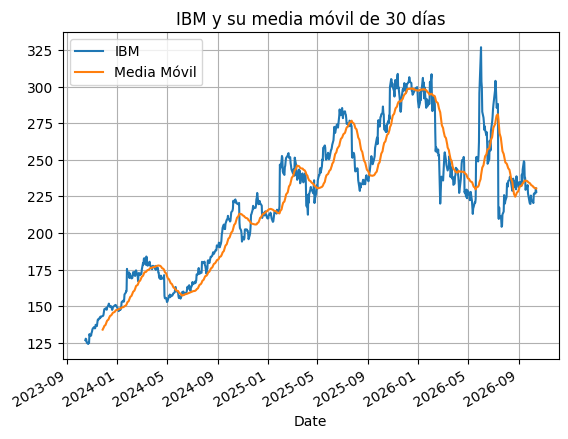

In [26]:
#Graficación de la media móvil para IBM
rollin_ibm = ibm.rolling(30).mean()
ax = ibm.plot(label="IBM")
rollin_ibm.plot(ax=ax, label="Media móvil de 30 días")
plt.legend(["IBM", "Media Móvil"])
plt.grid()
plt.title("IBM y su media móvil de 30 días")
plt.show()

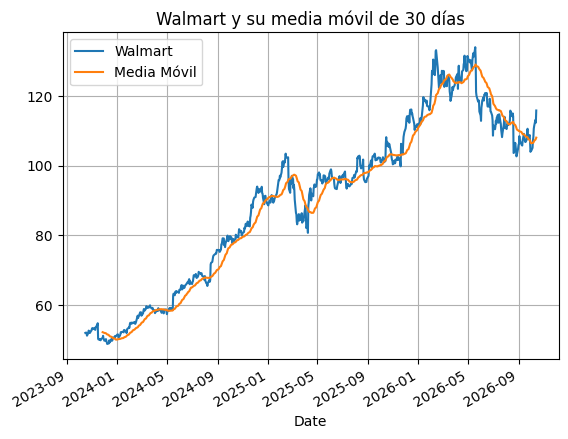

In [27]:
rollin_wmt = wmt.rolling(30).mean()
ax = wmt.plot(label="Walmart")
rollin_wmt.plot(ax=ax, label="Media móvil de 30 días")
plt.legend(["Walmart", "Media Móvil"])
plt.grid()
plt.title("Walmart y su media móvil de 30 días")
plt.show()

In [28]:
len_train = int(ibm.shape[0]*0.8)
len_train

601

In [29]:
train = ibm[0:len_train]
test = ibm[len_train:]
print("Dimensiones train:", train.shape)
print("Dimensiones test:", test.shape)

Dimensiones train: (601, 1)
Dimensiones test: (151, 1)


In [30]:
y_pred = ibm.copy()
y_pred = pd.DataFrame(y_pred)

y_pred["pronostico"] = ibm.rolling(30).mean()

y_pred_m = y_pred.copy()
y_pred_m["pronostico"][29] = "Na"

for contador in range(30, len(y_pred_m)):
    y_pred_m["pronostico"][contador] = y_pred["pronostico"][contador-1]

y_pred_m = pd.DataFrame(y_pred_m["pronostico"][len_train:])

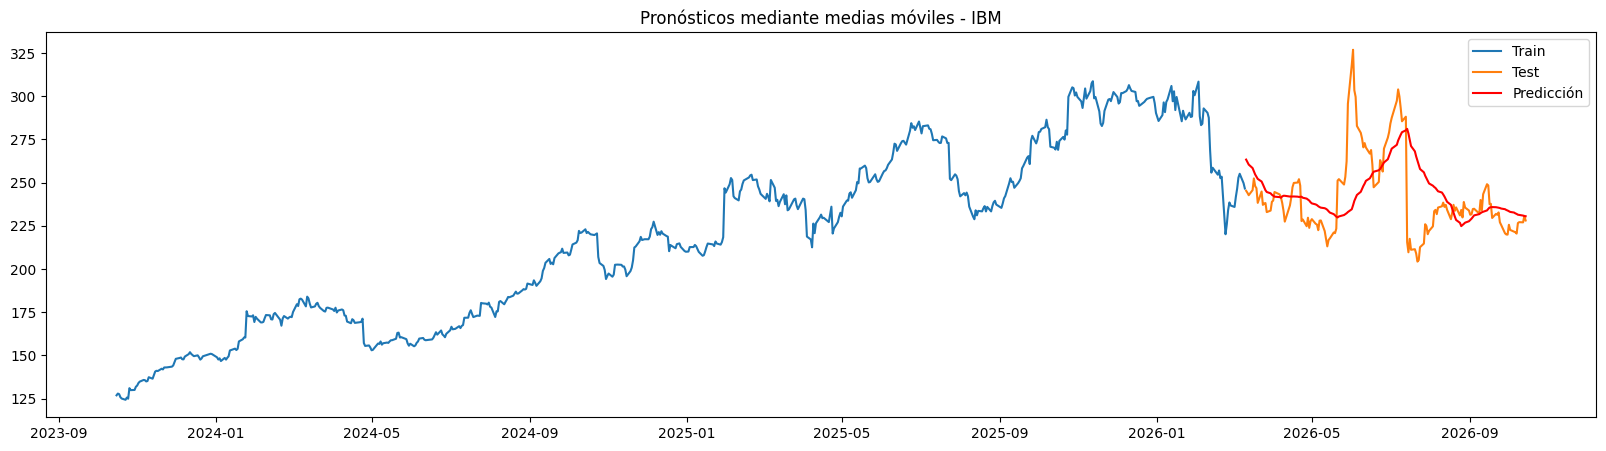

In [31]:
plt.figure(figsize=(20,5))
plt.grid
plt.plot(train, label="Train")
plt.plot(test, label="Test")
plt.plot(y_pred_m["pronostico"], label="Predicción", color="red")
plt.legend(loc="best")
plt.title("Pronósticos mediante medias móviles - IBM")
plt.show()

In [32]:
from sklearn.metrics import mean_squared_error

n = min(len(test), len(y_pred_m))
test_align = test.iloc[:n]
pred_align = y_pred_m.iloc[:n]

rmse = np.sqrt(mean_squared_error(test_align, pred_align)).round(2)
mape = (np.mean(np.abs(test_align.iloc[:, 0] - pred_align["pronostico"]) / test_align.iloc[:, 0]) * 100).round(2)

print("RMSE:", rmse)
print("MAPE:", mape, "%")

RMSE: 23.6
MAPE: 6.65 %


In [33]:
y_pred.tail(1)["pronostico"]

Date
2026-10-14    230.446667
Name: pronostico, dtype: float64